# Лабораторна робота 3. Машинне навчання
## Регресія: прогнозування вартості нерухомості

**Мета роботи:** виконати первинний аналіз даних, побудувати кілька моделей регресії, оцінити їхню якість та виконати підбір гіперпараметрів для моделі Random Forest.

### Датасет
Можна використати один із двох способів завантаження даних:

1. Завантажити файл з Google Drive:
https://drive.google.com/file/d/1u_-3X05st6uvrgQB1qNLyE8a7QjTJjvd/view?usp=sharing

2. Завантажити датасет з Kaggle:
https://www.kaggle.com/datasets/prokshitha/home-value-insights

> Посилання та вміст датасету на зовнішніх платформах можуть змінюватися.

## 1. Імпорт бібліотек
Імпортуйте бібліотеки, необхідні для роботи з даними, візуалізації та числових обчислень.

In [4]:
import os
import io
import zipfile
import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)


## 2. Завантаження даних
Завантажте файл двома способами.

In [5]:
if 'df' not in globals():
    url = 'https://www.kaggle.com/api/v1/datasets/download/prokshitha/home-value-insights'
    try:
        with urllib.request.urlopen(url, timeout=90) as response:
            archive_bytes = response.read()
        with zipfile.ZipFile(io.BytesIO(archive_bytes)) as archive:
            candidates = [name for name in archive.namelist() if name.lower().endswith('.csv')]
            if not candidates:
                raise FileNotFoundError('У завантаженому архіві немає CSV.')
            with archive.open(candidates[0]) as file:
                df = pd.read_csv(file)
        print(f'Завантажено з Kaggle: {candidates[0]}, розмір: {df.shape}')
    except Exception as error:
        raise RuntimeError('Не вдалося отримати CSV з Kaggle. Завантажте його за посиланням із шаблону та запустіть комірку 5.') from error
else:
    print('Використовуємо вже завантажений DataFrame df.')

required_columns = ['Square_Footage', 'Num_Bedrooms', 'Num_Bathrooms', 'Year_Built', 'Lot_Size', 'Garage_Size', 'Neighborhood_Quality', 'House_Price']
missing_columns = sorted(set(required_columns) - set(df.columns))
if missing_columns:
    raise ValueError(f'У CSV відсутні необхідні стовпці: {missing_columns}')


Використовуємо вже завантажений DataFrame df.


## 3. Опис ознак датасету

- **Square_Footage** — загальна житлова площа будинку.
- **Num_Bedrooms** — кількість спалень.
- **Num_Bathrooms** — кількість ванних кімнат.
- **Year_Built** — рік побудови будинку.
- **Lot_Size** — розмір земельної ділянки.
- **Garage_Size** — розмір гаража або кількість паркомісць.
- **Neighborhood_Quality** — оцінка якості району.
- **House_Price** — ціна будинку, цільова змінна.

## 4. Первинний аналіз даних

### Завдання 1. Перегляд даних
Виведіть перші рядки датасету та перегляньте його структуру.

In [6]:
display(df.head())
print(f'Рядків: {len(df)}, стовпців: {df.shape[1]}')
df.info()


,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.599637,0,5,2.623829e+05
1,4272,3,3,2016,4.753014,1,6,9.852609e+05
2,3592,1,2,2016,3.634823,0,9,7.779774e+05
3,966,1,2,1977,2.730667,1,8,2.296989e+05
4,4926,2,1,1993,4.699073,0,8,1.041741e+06


Рядків: 1000, стовпців: 8
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Square_Footage        1000 non-null   int64  
 1   Num_Bedrooms          1000 non-null   int64  
 2   Num_Bathrooms         1000 non-null   int64  
 3   Year_Built            1000 non-null   int64  
 4   Lot_Size              1000 non-null   float64
 5   Garage_Size           1000 non-null   int64  
 6   Neighborhood_Quality  1000 non-null   int64  
 7   House_Price           1000 non-null   float64
dtypes: float64(2), int64(6)
memory usage: 62.6 KB


### Завдання 2. Перевірка дублікатів
Визначте кількість дубльованих рядків.

In [7]:
duplicates_count = df.duplicated().sum()
print(f'Кількість дубльованих рядків: {duplicates_count}')


Кількість дубльованих рядків: 0


### Завдання 3. Перевірка пропущених значень
Визначте кількість пропущених значень у кожному стовпці.

In [8]:
missing_count = df.isna().sum()
display(missing_count.rename('Кількість пропусків').to_frame())


,Кількість пропусків
Square_Footage,0
Num_Bedrooms,0
Num_Bathrooms,0
Year_Built,0
Lot_Size,0
Garage_Size,0
Neighborhood_Quality,0
House_Price,0


### Завдання 4. Описова статистика
Виведіть основні статистичні характеристики числових ознак.

In [9]:
display(df.describe().T)


,count,mean,std,min,25%,50%,75%,max
Square_Footage,1000.0,2815.422000,1255.514921,503.000000,1749.500000,2862.500000,3849.500000,4.999000e+03
Num_Bedrooms,1000.0,2.990000,1.427564,1.000000,2.000000,3.000000,4.000000,5.000000e+00
Num_Bathrooms,1000.0,1.973000,0.820332,1.000000,1.000000,2.000000,3.000000,3.000000e+00
Year_Built,1000.0,1986.550000,20.632916,1950.000000,1969.000000,1986.000000,2004.250000,2.022000e+03
Lot_Size,1000.0,2.778087,1.297903,0.506058,1.665946,2.809740,3.923317,4.989303e+00
Garage_Size,1000.0,1.022000,0.814973,0.000000,0.000000,1.000000,2.000000,2.000000e+00
Neighborhood_Quality,1000.0,5.615000,2.887059,1.000000,3.000000,6.000000,8.000000,1.000000e+01
House_Price,1000.0,618861.018647,253568.058375,111626.853424,401648.228909,628267.291129,827141.277637,1.108237e+06


## 5. Аналіз окремих ознак

### Завдання 5. Ознака `Neighborhood_Quality`
Виведіть частоти значень ознаки `Neighborhood_Quality`.

In [10]:
display(df['Neighborhood_Quality'].value_counts(dropna=False).sort_index().rename('Кількість').to_frame())


,Кількість
Neighborhood_Quality,
1,91
2,105
3,85
4,99
5,109
6,101
7,102
8,97
9,88


### Завдання 6. Візуалізація `Neighborhood_Quality`
Побудуйте діаграму розподілу значень цієї ознаки.

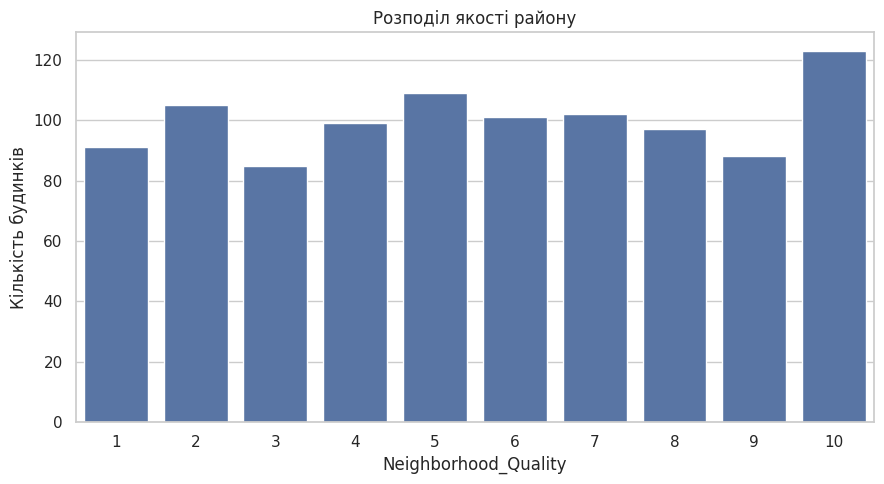

In [11]:
plt.figure(figsize=(9, 5))
sns.countplot(data=df, x='Neighborhood_Quality', order=sorted(df['Neighborhood_Quality'].dropna().unique()))
plt.title('Розподіл якості району')
plt.xlabel('Neighborhood_Quality')
plt.ylabel('Кількість будинків')
plt.tight_layout()
plt.show()


### Завдання 7. Ознака `Num_Bathrooms`
Виведіть частоти значень кількості ванних кімнат.

In [12]:
display(df['Num_Bathrooms'].value_counts(dropna=False).sort_index().rename('Кількість').to_frame())


,Кількість
Num_Bathrooms,
1,350
2,327
3,323


### Завдання 8. Візуалізація `Num_Bathrooms`
Побудуйте діаграму розподілу кількості ванних кімнат.

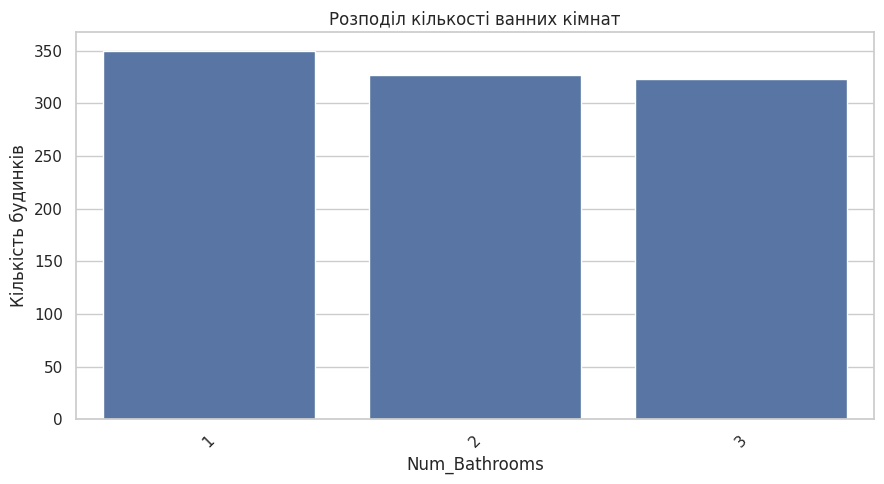

In [13]:
plt.figure(figsize=(9, 5))
sns.countplot(data=df, x='Num_Bathrooms', order=sorted(df['Num_Bathrooms'].dropna().unique()))
plt.title('Розподіл кількості ванних кімнат')
plt.xlabel('Num_Bathrooms')
plt.ylabel('Кількість будинків')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### Додаткове завдання
За потреби побудуйте попарні графіки числових ознак і коротко проаналізуйте можливі залежності.

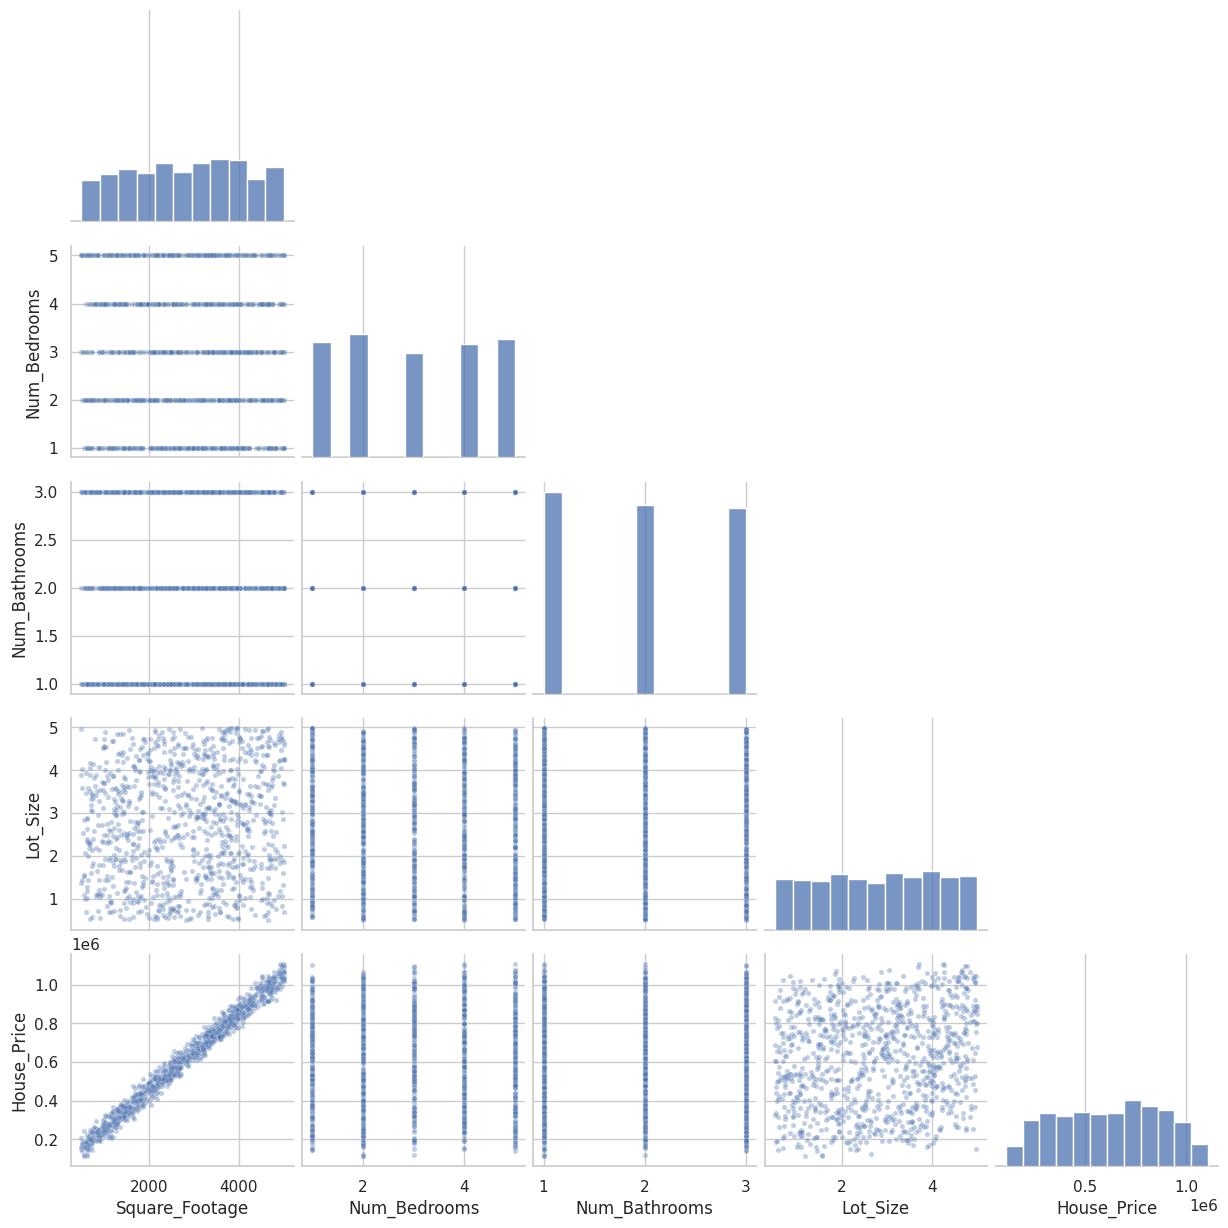

In [14]:
selected = ['Square_Footage', 'Num_Bedrooms', 'Num_Bathrooms', 'Lot_Size', 'House_Price']
sns.pairplot(df[selected].dropna(), corner=True, plot_kws={'alpha': 0.35, 's': 14})
plt.show()


## 6. Кореляційний аналіз

### Завдання 9. Матриця кореляції
Побудуйте кореляційну матрицю для числових ознак та відобразіть її у вигляді теплової карти.

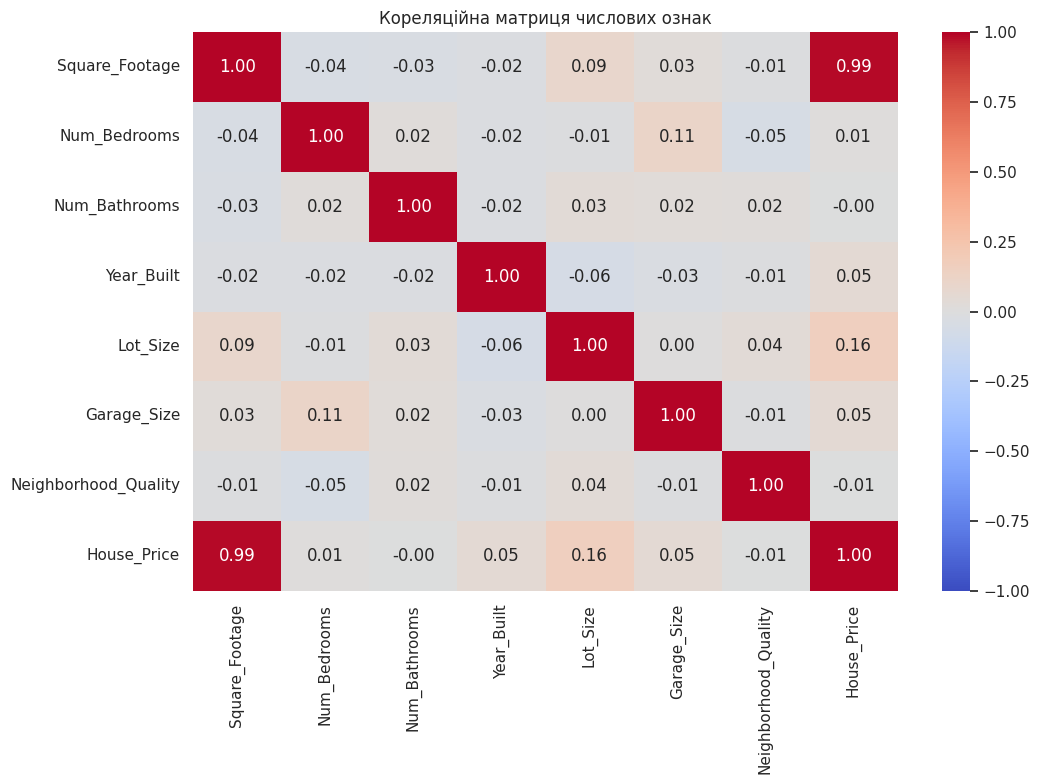

In [15]:
numeric_df = df.select_dtypes(include='number')
corr = numeric_df.corr()
plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Кореляційна матриця числових ознак')
plt.tight_layout()
plt.show()


### Завдання 10. Кореляція з цільовою змінною
Виведіть кореляцію кожної ознаки з `House_Price`, відсортувавши значення за спаданням.

In [16]:
price_corr = corr['House_Price'].sort_values(ascending=False)
display(price_corr.rename('Кореляція з ціною').to_frame())


,Кореляція з ціною
House_Price,1.000000
Square_Footage,0.991261
Lot_Size,0.160412
Garage_Size,0.052133
Year_Built,0.051967
Num_Bedrooms,0.014633
Num_Bathrooms,-0.001862
Neighborhood_Quality,-0.007770


## 7. Побудова моделей регресії

### Завдання 11. Імпорт інструментів Scikit-learn
Імпортуйте засоби для:
- поділу вибірки;
- масштабування ознак;
- побудови Linear Regression, Ridge, Lasso, Random Forest та Gradient Boosting;
- створення Pipeline;
- обчислення R², MAE та MSE.

In [17]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error


### Завдання 12. Формування `X` і `y`
Відокремте ознаки від цільової змінної `House_Price`.

In [18]:
X = df.drop(columns=['House_Price']).select_dtypes(include='number')
y = pd.to_numeric(df['House_Price'], errors='coerce')
valid_target = y.notna()
X = X.loc[valid_target]
y = y.loc[valid_target]
print('Ознаки:', X.columns.tolist())
print('Цільова змінна: House_Price')


Ознаки: ['Square_Footage', 'Num_Bedrooms', 'Num_Bathrooms', 'Year_Built', 'Lot_Size', 'Garage_Size', 'Neighborhood_Quality']
Цільова змінна: House_Price


### Завдання 13. Поділ даних
Поділіть дані на навчальну і тестову вибірки у співвідношенні 80/20. Для відтворюваності використайте `random_state=42`.

In [19]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f'Навчальна вибірка: {len(X_train)} рядків, тестова: {len(X_test)} рядків')


Навчальна вибірка: 800 рядків, тестова: 200 рядків


### Завдання 14. Створення моделей
Створіть п’ять моделей:
1. Linear Regression;
2. Ridge;
3. Lasso;
4. Random Forest Regressor;
5. Gradient Boosting Regressor.

Для лінійних моделей використайте `Pipeline` зі `StandardScaler`. Для деревоподібних моделей масштабування не потрібне.

In [20]:
def scaled_model(regressor):
    return Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('regressor', regressor)
    ])

def tree_model(regressor):
    return Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('regressor', regressor)
    ])

models = {
    'Linear Regression': scaled_model(LinearRegression()),
    'Ridge': scaled_model(Ridge(alpha=1.0)),
    'Lasso': scaled_model(Lasso(alpha=1.0, max_iter=20000)),
    'Random Forest': tree_model(RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)),
    'Gradient Boosting': tree_model(GradientBoostingRegressor(random_state=42))
}


### Завдання 15. Навчання та оцінювання моделей
Для кожної моделі:
- виконайте навчання на тренувальній вибірці;
- отримайте прогноз для тестової вибірки;
- обчисліть `R²`, `MAE`, `MSE`;
- збережіть результати для подальшого порівняння.

In [21]:
metrics = []
predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    predictions[name] = y_pred
    metrics.append({
        'Модель': name,
        'R²': r2_score(y_test, y_pred),
        'MAE': mean_absolute_error(y_test, y_pred),
        'MSE': mean_squared_error(y_test, y_pred)
    })
results_df = pd.DataFrame(metrics).sort_values('R²', ascending=False).reset_index(drop=True)
display(results_df.round(3))


,Модель,R²,MAE,MSE
0,Linear Regression,0.998,8174.584,1.014348e+08
1,Lasso,0.998,8174.748,1.014366e+08
2,Ridge,0.998,8241.587,1.024810e+08
3,Gradient Boosting,0.997,12305.218,2.249656e+08
4,Random Forest,0.994,16114.290,3.941317e+08


### Завдання 16. Графічне порівняння прогнозів
Для кожної моделі побудуйте графік **фактичні значення vs прогнозовані значення**. Додайте лінію ідеального прогнозу.

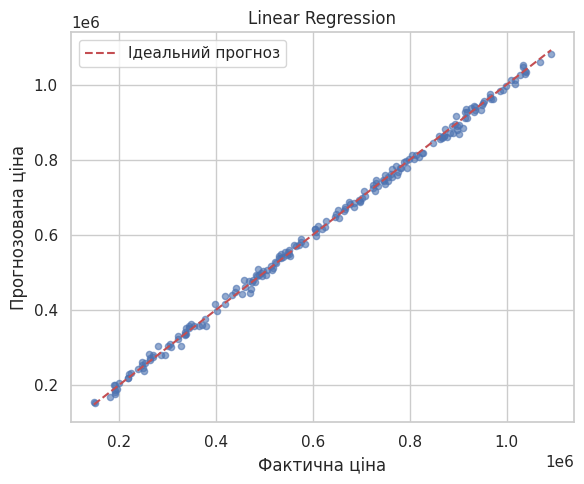

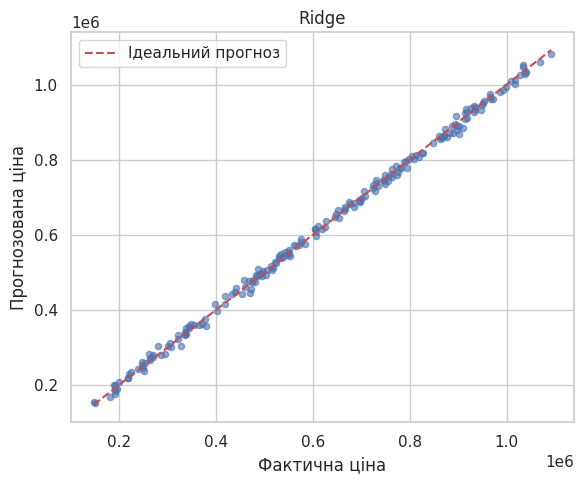

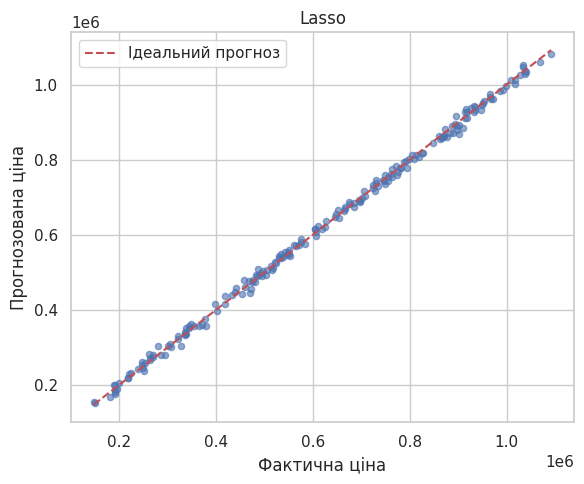

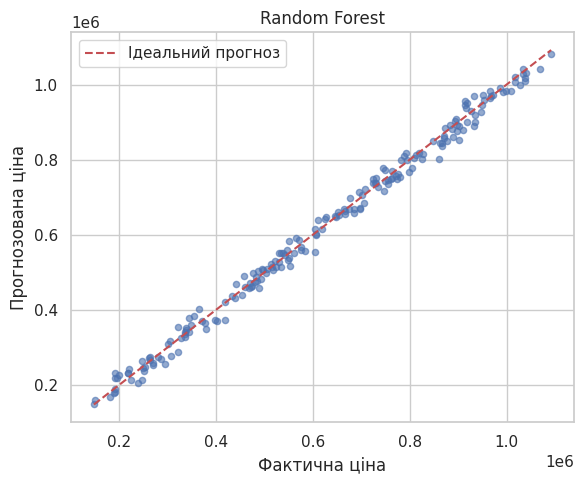

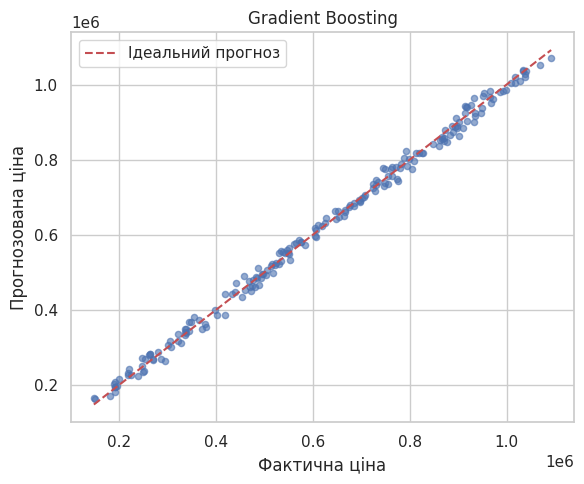

In [22]:
for name, y_pred in predictions.items():
    plt.figure(figsize=(6, 5))
    plt.scatter(y_test, y_pred, alpha=0.6, s=20)
    minimum = min(y_test.min(), np.min(y_pred))
    maximum = max(y_test.max(), np.max(y_pred))
    plt.plot([minimum, maximum], [minimum, maximum], 'r--', label='Ідеальний прогноз')
    plt.xlabel('Фактична ціна')
    plt.ylabel('Прогнозована ціна')
    plt.title(name)
    plt.legend()
    plt.tight_layout()
    plt.show()


## 8. Підбір гіперпараметрів Random Forest

### Завдання 17. GridSearchCV
Виконайте підбір оптимальних параметрів для `RandomForestRegressor` за допомогою `GridSearchCV`.

Дослідіть щонайменше такі параметри:
- `n_estimators`;
- `max_features`;
- `max_depth`;
- `min_samples_split`.

Використайте крос-валідацію та метрику `R²`.

In [23]:
param_grid = {
    'regressor__n_estimators': [50, 100],
    'regressor__max_features': [0.7, 1.0],
    'regressor__max_depth': [None, 10, 20],
    'regressor__min_samples_split': [2, 5]
}
rf_pipeline = tree_model(RandomForestRegressor(random_state=42, n_jobs=1))
grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    scoring='r2',
    cv=3,
    n_jobs=-1,
    refit=True
)
grid_search.fit(X_train, y_train)
print('Найкращі параметри:', {key.replace('regressor__', ''): value for key, value in grid_search.best_params_.items()})
print(f'Найкращий середній R² на крос-валідації: {grid_search.best_score_:.4f}')


Найкращі параметри: {'max_depth': 10, 'max_features': 1.0, 'min_samples_split': 2, 'n_estimators': 100}
Найкращий середній R² на крос-валідації: 0.9913


### Завдання 18. Оптимізована модель Random Forest
Створіть нову модель з найкращими параметрами, навчіть її та обчисліть `R²`, `MAE`, `MSE` на тестовій вибірці.

In [24]:
optimized_rf = grid_search.best_estimator_
optimized_pred = optimized_rf.predict(X_test)
optimized_metrics = {
    'Модель': 'Random Forest (оптимізована)',
    'R²': r2_score(y_test, optimized_pred),
    'MAE': mean_absolute_error(y_test, optimized_pred),
    'MSE': mean_squared_error(y_test, optimized_pred)
}
display(pd.DataFrame([optimized_metrics]).round(3))


,Модель,R²,MAE,MSE
0,Random Forest (оптимізована),0.994,16073.021,3.974064e+08


### Завдання 19. Порівняння Random Forest до і після оптимізації
Порівняйте значення `R²`, `MAE` і `MSE` для базової та оптимізованої моделей.

In [25]:
baseline_rf = results_df.loc[results_df['Модель'] == 'Random Forest'].iloc[0].to_dict()
comparison = pd.DataFrame([baseline_rf, optimized_metrics]).set_index('Модель')
display(comparison.round(3))
print('Зміни після оптимізації:')
for metric in ['R²', 'MAE', 'MSE']:
    delta = optimized_metrics[metric] - baseline_rf[metric]
    print(f'{metric}: {delta:+.4f}')


,R²,MAE,MSE
Модель,,,
Random Forest,0.994,16114.290,3.941317e+08
Random Forest (оптимізована),0.994,16073.021,3.974064e+08


Зміни після оптимізації:
R²: -0.0001
MAE: -41.2687
MSE: +3274676.7275


### Завдання 20. Аналіз оптимізації

Після виконання всіх попередніх комірок наведений нижче код автоматично формує висновок на основі фактичних метрик на тестовій вибірці.

In [26]:
r2_delta = optimized_metrics['R²'] - baseline_rf['R²']
mae_delta = optimized_metrics['MAE'] - baseline_rf['MAE']
mse_delta = optimized_metrics['MSE'] - baseline_rf['MSE']
summary = 'покращила' if r2_delta > 0 and mae_delta < 0 else 'не забезпечила однозначного покращення'
display(Markdown(f"""**Висновок до завдання 20.** Оптимізація {summary} якість Random Forest на тестовій вибірці. Зміна R²: {r2_delta:+.4f}, MAE: {mae_delta:+.2f}, MSE: {mse_delta:+.2f}. Оптимізовану модель доцільно використовувати, якщо вона має кращі результати на незалежних даних; сам факт пошуку параметрів не гарантує покращення."""))


**Висновок до завдання 20.** Оптимізація не забезпечила однозначного покращення якість Random Forest на тестовій вибірці. Зміна R²: -0.0001, MAE: -41.27, MSE: +3274676.73. Оптимізовану модель доцільно використовувати, якщо вона має кращі результати на незалежних даних; сам факт пошуку параметрів не гарантує покращення.

## 9. Аналіз прогнозів лінійної регресії

### Завдання 21. Таблиця прогнозів
Для моделі Linear Regression створіть таблицю з трьома стовпцями:
- фактична ціна;
- прогнозована ціна;
- похибка у відсотках.

Виведіть 10 випадкових рядків.

In [27]:
actual = y_test.to_numpy()
predicted = predictions['Linear Regression']
error_percent = np.where(np.abs(actual) > 1e-12, np.abs(actual - predicted) / np.abs(actual) * 100, np.nan)
forecast_table = pd.DataFrame({
    'Фактична ціна': actual,
    'Прогнозована ціна': predicted,
    'Похибка, %': error_percent
}, index=y_test.index)
display(forecast_table.sample(n=min(10, len(forecast_table)), random_state=42).round(2))
print(f'Середня відносна абсолютна похибка: {np.nanmean(error_percent):.2f}%')


,Фактична ціна,Прогнозована ціна,"Похибка, %"
436,1068538.11,1059729.02,0.82
899,194353.74,187868.55,3.34
346,270230.64,279715.82,3.51
60,986006.86,981949.27,0.41
867,953339.73,957382.95,0.42
432,914555.75,909764.27,0.52
543,746167.73,742469.14,0.50
361,646766.29,654445.55,1.19
486,523323.07,524605.44,0.25
277,1008539.16,1011343.64,0.28


Середня відносна абсолютна похибка: 1.66%


## 10. Висновки

Загальний висновок формується за результатами виконання ноутбука. Він використовує лише фактично обчислені значення метрик.

In [29]:
all_results = pd.concat([results_df, pd.DataFrame([optimized_metrics])], ignore_index=True)
best_row = all_results.sort_values(['R²', 'MAE'], ascending=[False, True]).iloc[0]
mean_price = y_test.mean()
mae_relative = 100 * best_row['MAE'] / mean_price if mean_price != 0 else float('nan')
strongest_factor = price_corr.drop('House_Price').abs().idxmax()
display(Markdown(f"""**Загальний висновок.** Під час лабораторної роботи проведено первинний аналіз даних, перевірку дублікатів і пропусків, візуалізацію розподілів та кореляційний аналіз. Побудовано моделі Linear Regression, Ridge, Lasso, Random Forest та Gradient Boosting. Найкращий результат на тестовій вибірці за R² показала **{best_row['Модель']}** (R² = **{best_row['R²']:.4f}**, MAE = **{best_row['MAE']:.2f}**, MSE = **{best_row['MSE']:.2f}**). MAE становить приблизно **{mae_relative:.2f}%** від середньої фактичної ціни у тестовій вибірці (це не MAPE). Після підбору гіперпараметрів Random Forest різниця R² становить **{r2_delta:+.4f}**, що дає змогу оцінити практичний ефект оптимізації. Серед наведених ознак найбільшу за модулем лінійну кореляцію з ціною має **{strongest_factor}**. На точність прогнозування можуть впливати обсяг і якість даних, відсутні ознаки, викиди та вибір параметрів моделі."""))


**Загальний висновок.** Під час лабораторної роботи проведено первинний аналіз даних, перевірку дублікатів і пропусків, візуалізацію розподілів та кореляційний аналіз. Побудовано моделі Linear Regression, Ridge, Lasso, Random Forest та Gradient Boosting. Найкращий результат на тестовій вибірці за R² показала **Linear Regression** (R² = **0.9984**, MAE = **8174.58**, MSE = **101434798.51**). MAE становить приблизно **1.32%** від середньої фактичної ціни у тестовій вибірці (це не MAPE). Після підбору гіперпараметрів Random Forest різниця R² становить **-0.0001**, що дає змогу оцінити практичний ефект оптимізації. Серед наведених ознак найбільшу за модулем лінійну кореляцію з ціною має **Square_Footage**. На точність прогнозування можуть впливати обсяг і якість даних, відсутні ознаки, викиди та вибір параметрів моделі.